In [1]:
# 0. 의존성 점검·설치 (처음 한 번). 설치 후에는 커널을 재시작하세요.
import importlib.metadata as _metadata
from pathlib import Path as _Path
import subprocess as _subprocess
import sys as _sys
from packaging.requirements import Requirement as _Requirement

_roots = [_Path.cwd(), *_Path.cwd().parents]
_requirements = next((candidate for base in _roots
                      for candidate in [base / 'src' / 'part5_bed_exit' / 'requirements.txt',
                                        base / 'requirements.txt']
                      if candidate.is_file() and candidate.parent.name == 'part5_bed_exit'), None)
if _requirements is None:
    raise RuntimeError('이 저장소 또는 Part 5 폴더에서 노트북을 실행하세요.')
_needed = []
for _line in _requirements.read_text().splitlines():
    _line = _line.split('#', 1)[0].strip()
    if not _line:
        continue
    _requirement = _Requirement(_line)
    try:
        _version = _metadata.version(_requirement.name)
    except _metadata.PackageNotFoundError:
        _needed.append(_line)
        continue
    if not _requirement.specifier.contains(_version):
        _needed.append(_line)
print('현재 커널 Python:', _sys.executable)
if _needed:
    print('설치/업데이트할 의존성:', ', '.join(_needed))
    _subprocess.check_call([_sys.executable, '-m', 'pip', 'install', '--upgrade',
                           '-r', str(_requirements)])
    raise RuntimeError('설치 완료. Kernel → Restart Kernel로 재시작한 뒤 이 셀부터 다시 실행하세요.')
if 'matplotlib' in _sys.modules and not hasattr(_sys.modules['matplotlib'].rcParams, '_get'):
    raise RuntimeError('이 커널에 이전 Matplotlib이 남아 있습니다. Kernel → Restart Kernel 후 다시 실행하세요.')
print('의존성 준비 완료. 다음 셀부터 실행하세요.')
print('Matplotlib:', _metadata.version('matplotlib'),
      '| matplotlib-inline:', _metadata.version('matplotlib-inline'))


현재 커널 Python: /home/hv-02/venvs/rokey_venv/bin/python
의존성 준비 완료. 다음 셀부터 실행하세요.
Matplotlib: 3.11.2 | matplotlib-inline: 0.2.2


/home/hv-02/venvs/rokey_venv/lib/python3.12/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


입력 이미지 자동 연결: /home/hv-02/workspaces/bad_autonoumous_delivery/src/part5_bed_exit/data/sample/bed_exit_sample.jpg
BGR uint8: (1080, 1920, 3) uint8


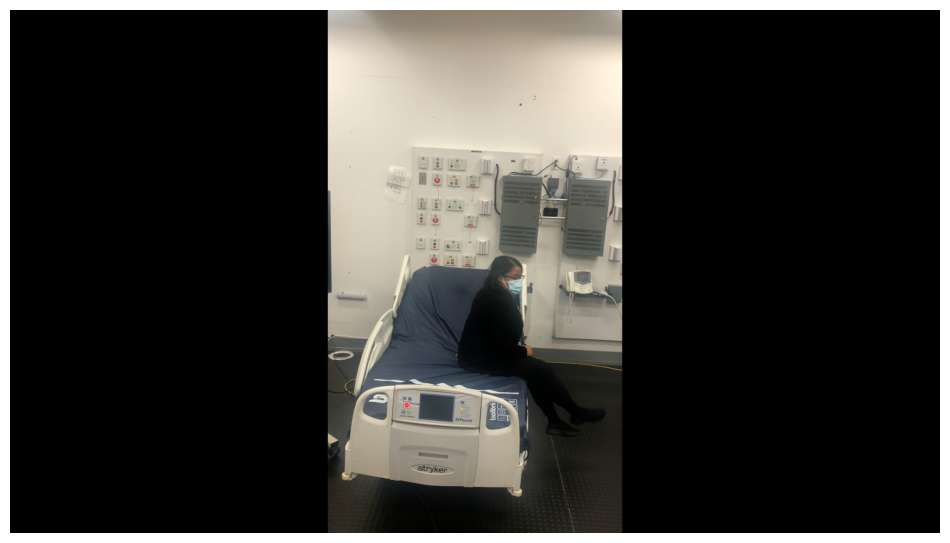

In [2]:
import json
import os
from pathlib import Path
import sys

roots = [Path.cwd(), *Path.cwd().parents]
PACKAGE_ROOT = next((candidate for root in roots
                     for candidate in [root / 'src' / 'part5_bed_exit', root]
                     if (candidate / 'part5_bed_exit' / 'bed_exit_method.py').is_file()), None)
if PACKAGE_ROOT is None:
    raise RuntimeError('이 저장소 또는 Part 5 폴더에서 노트북을 실행하세요.')
sys.path.insert(0, str(PACKAGE_ROOT))

import cv2
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
from part5_bed_exit.downloads import download_file, download_models
from part5_bed_exit.methods.bed_exit_core import (
    MODEL_FILES, PolygonROI, JudgmentUnavailable, make_method,
)

IMAGE_URL = 'https://source.roboflow.com/8WwkR5B0rZUWRmkeXpaFrnEVKFg2/03Fbb7vK4CXsAkZqUllT/original.jpg'
IMAGE_PATH = PACKAGE_ROOT / 'data' / 'sample' / 'bed_exit_sample.jpg'
IMAGE_PATH = download_file(IMAGE_URL, IMAGE_PATH, max_bytes=10 * 1024**2)
frame = cv2.imread(str(IMAGE_PATH))
if frame is None:
    raise RuntimeError(f'이미지를 읽을 수 없습니다: {IMAGE_PATH}')
print('입력 이미지 자동 연결:', IMAGE_PATH)
print('BGR uint8:', frame.shape, frame.dtype)
plt.figure(figsize=(12, 7))
plt.imshow(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
plt.axis('off')
plt.show()

## 같은 이미지 → 네 클래스의 judge(frame)

아래 다각형과 환자 선택 박스는 **이 샘플의 연결 확인을 위한 예시 좌표**다.
모델은 사전학습 가중치를 사용하며 학습하지 않는다. 이 좌표를 실제 카메라나 정량평가의 정답으로 사용하지 않는다.

이미지 한 장이므로 다수결 전 원판정만 출력한다. ROS의 5프레임 다수결은 기존 코드에 그대로 유지된다.
같은 사진을 다섯 번 복제해 시간 성능을 평가하지 않는다.

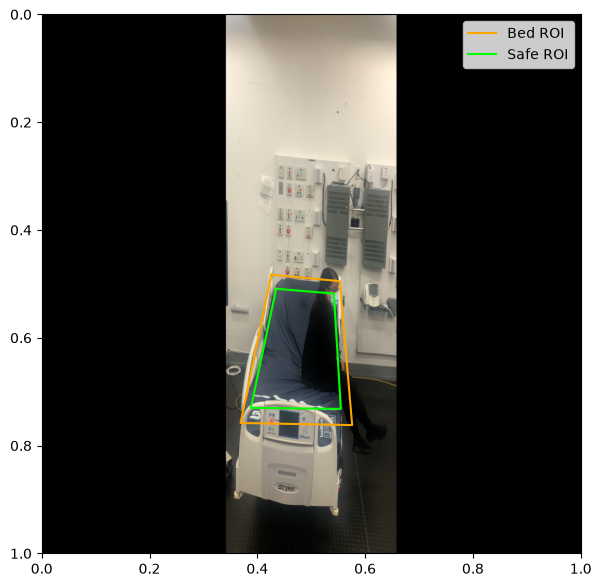

I0000 00:00:1794731479.499073   39355 gl_context_egl.cc:85] Successfully initialized EGL. Major : 1 Minor: 5
W0000 00:00:1794731479.499100   39355 gl_context_egl.cc:184] Creating a context with OpenGL ES 3 failed: UNKNOWN: ; eglChooseConfig() returned no matching EGL configuration for RGBA8888 D16 ES3 request. 
W0000 00:00:1794731479.499103   39355 gl_context_egl.cc:186] Fall back on OpenGL ES 2.
I0000 00:00:1794731479.499112   39355 task_runner.cc:85] GPU suport is not available: UNKNOWN: ; eglChooseConfig() returned no matching EGL configuration for RGBA8888 D16 ES2 request. 
I0000 00:00:1794731479.502475   39355 gl_context_egl.cc:85] Successfully initialized EGL. Major : 1 Minor: 5
W0000 00:00:1794731479.502493   39355 gl_context_egl.cc:184] Creating a context with OpenGL ES 3 failed: UNKNOWN: ; eglChooseConfig() returned no matching EGL configuration for RGBA8888 D16 ES3 request. 
W0000 00:00:1794731479.502495   39355 gl_context_egl.cc:186] Fall back on OpenGL ES 2.
I0000 00:00:179

[{'method': 'detection',
  'class': 'DetectionROI',
  'raw_bool': True,
  'state': 'EXIT',
  'reason': 'box_outside_fraction'},
 {'method': 'segmentation',
  'class': 'SegmentationROI',
  'raw_bool': True,
  'state': 'EXIT',
  'reason': 'mask_outside_fraction'},
 {'method': 'yolo_pose',
  'class': 'YoloPoseROI',
  'raw_bool': True,
  'state': 'EXIT',
  'reason': 'visible_keypoint_outside'},
 {'method': 'mediapipe_pose',
  'class': 'MediaPipePoseROI',
  'raw_bool': True,
  'state': 'EXIT',
  'reason': 'visible_keypoint_outside'}]

In [3]:
MODEL_DIR = Path(os.environ.get('BED_EXIT_MODEL_DIR', str(PACKAGE_ROOT / 'models'))).expanduser().resolve()
if any(not (MODEL_DIR / filename).is_file() for filename in MODEL_FILES.values()):
    download_models(MODEL_DIR)

bed_roi = PolygonROI([[.426,.483],[.553,.495],[.576,.762],[.369,.758]])
safe_roi = PolygonROI([[.435,.509],[.542,.518],[.555,.732],[.388,.730]])
initial_patient_bbox = [.50,.50,.58,.72]

fig, ax = plt.subplots(figsize=(12, 7))
ax.imshow(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB), extent=(0,1,1,0))
for label, roi, color in [('Bed ROI', bed_roi, 'orange'), ('Safe ROI', safe_roi, 'lime')]:
    points = np.vstack([roi.vertices, roi.vertices[0]])
    ax.plot(points[:,0], points[:,1], color=color, label=label)
ax.legend()
plt.show()

results = []
for method_name in MODEL_FILES:
    detector = None
    try:
        detector = make_method(method_name, bed_roi, safe_roi, MODEL_DIR,
                               initial_bbox=initial_patient_bbox, device='cpu', policy='any_body')
        unsafe = detector.judge(frame.copy())
        assert type(unsafe) is bool
        results.append({'method': method_name, 'class': type(detector).__name__,
                        'raw_bool': unsafe, 'state': 'EXIT' if unsafe else 'SAFE',
                        'reason': detector.last.reason})
    except JudgmentUnavailable as exc:
        results.append({'method': method_name, 'raw_bool': None, 'reason': str(exc)})
    except ModuleNotFoundError as exc:
        results.append({'method': method_name, 'raw_bool': None,
                        'reason': f'현재 커널에 {exc.name} 미설치. 첫 셀의 설치 명령 후 커널을 재시작하세요.'})
    finally:
        if detector is not None:
            detector.close()
display(results)